# EDA PHẦN 2: Relationships, Feature Engineering, Summary

## Import Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

## Load dữ liệu

Đọc dữ liệu đầu ra từ bước EDA phần 1 để tiếp tục phân tích quan hệ giữa các biến

In [2]:
df = pd.read_csv('../data/PhamVietTien_eda_phan1.csv', dtype={'TransactionID': str}, parse_dates=['Transaction Date'])
df.shape

C:\Users\HOANG\AppData\Local\Temp\ipykernel_22952\2373988163.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/PhamVietTien_eda_phan1.csv', dtype={'TransactionID': str}, parse_dates=['Transaction Date'])


(158656, 8)

# Bước 5: Relationships (Quan hệ giữa các biến)

## 5.1. Numerical vs Numerical - Ma trận tương quan (Heatmap)

Kiểm tra mối quan hệ tuyến tính giữa `Quantity`, `Price` và `Sales Amount`

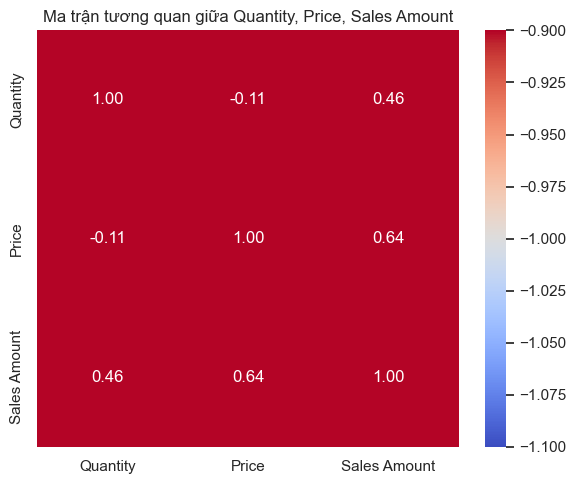

In [3]:
numeric_cols = ['Quantity', 'Price', 'Sales Amount']
corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=-1, fmt='.2f', ax=ax)
plt.title('Ma trận tương quan giữa Quantity, Price, Sales Amount')
plt.tight_layout()
plt.show()

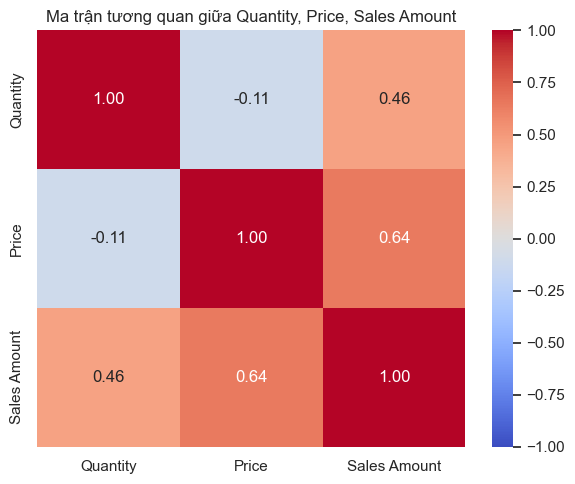

In [6]:
numeric_cols = ['Quantity', 'Price', 'Sales Amount']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Ma trận tương quan giữa Quantity, Price, Sales Amount')
plt.tight_layout()
plt.show()


**So what?** `Price` tương quan mạnh với `Sales Amount` (vì Sales Amount = Quantity x Price); `Quantity` và `Price` gần như không liên hệ - khách mua nhiều hay ít không phụ thuộc giá món đó đắt hay rẻ

## 5.2. Categorical vs Numerical - Price theo Source

Vì 2 nguồn dữ liệu chênh lệch số dòng rất lớn (Cafe Sales ít, Coffe Shop Sales nhiều), dùng Violin plot để so sánh **hình dạng phân phối** thay vì so sánh số lượng

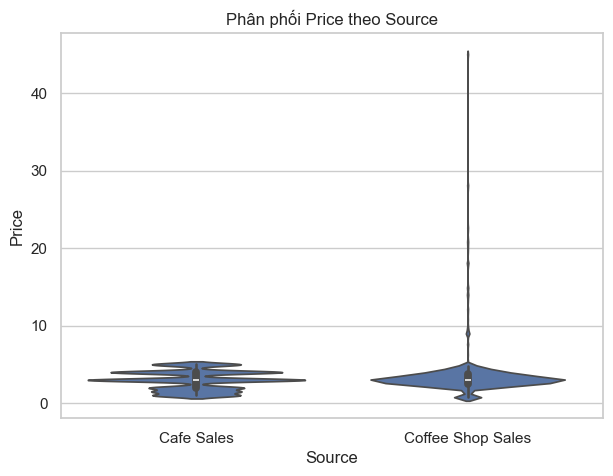

In [7]:
plt.figure(figsize=(7,5))
sns.violinplot(data=df, x='Source', y='Price')
plt.title('Phân phối Price theo Source')
plt.show()

**So what?** Coffee Shop Sales giá tập trung quanh mức 3 nhưng có đuôi dài tới 45, Cafe Sales giá thấp và đồng đều hơn - nên tách riêng theo Source khi tính doanh thu trung bình, không gộp chung

## 5.3. Categorical vs Categorical - Store Location theo Source

Dùng **tỷ lệ phần trăm (rate)** trong từng Source thay vì đếm số lượng thô, vì Coffee Shop Sales có số dòng gấp ~15 lần Cafe Sales nên so đếm trực tiếp sẽ sai lệch

In [8]:
duphong_rate = pd.crosstab(df['Source'], df['Store Location'], normalize='index') * 100
duphong_rate.round(1)

Store Location,Astoria,Hell's Kitchen,In-store,Lower Manhattan,Takeaway
Source,,,,,
Cafe Sales,0.0,0.0,30.1,0.0,69.9
Coffee Shop Sales,33.9,34.0,0.0,32.0,0.0


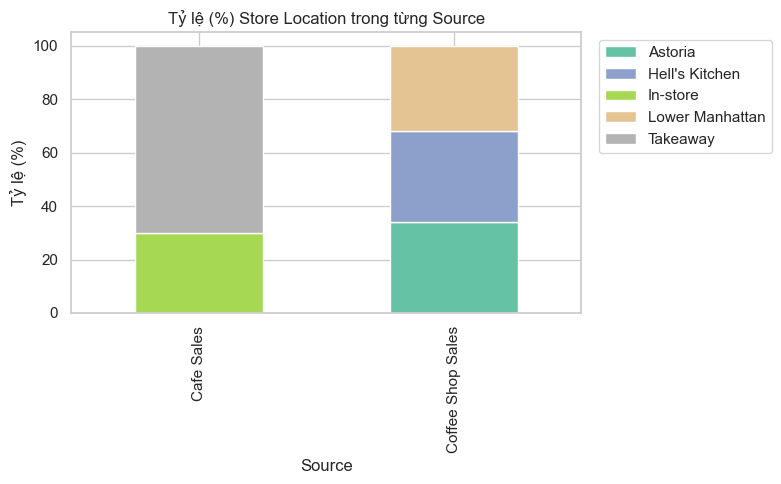

In [9]:
duphong_rate.plot(kind='bar', stacked=True, figsize=(8,5), colormap='Set2')
plt.title('Tỷ lệ (%) Store Location trong từng Source')
plt.ylabel('Tỷ lệ (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**So what?** `Store Location` gộp 2 loại thông tin khác bản chất: Coffe Shop Sales dùng tên địa điểm (Hell's Kitchen...), Cafe Sales dùng hình thức phục vụ (Takeaway/In-store) - 2 Source không có điểm chung ở cột này, là giới hạn của dữ liệu chứ không phải lỗi tính toán 

# Bước 6: Feature Engineering

## 6.1. Tách biến thời gian từ Transaction Date

In [10]:
df['Month'] = df['Transaction Date'].dt.month
df['Weekday'] = df['Transaction Date'].dt.day_name()
df[['Transaction Date', 'Month', 'Weekday']].head()

,Transaction Date,Month,Weekday
0,2023-09-08,9,Friday
1,2023-05-16,5,Tuesday
2,2023-07-19,7,Wednesday
3,2023-04-27,4,Thursday
4,2023-06-11,6,Sunday


## 6.2. Binning - Phân nhóm Price thành Low/Medium/High

In [11]:
df['Price Range'] = pd.cut(
    df['Price'],
    bins=[0, 2.5, 5, df['Price'].max()],
    labels=['Low', 'Medium', 'High']
)
df['Price Range'].value_counts()

Price Range
Medium    103288
Low        51156
High        4212
Name: count, dtype: int64

## 6.3. Dummy Variables - mã hóa Source

In [12]:
df_dummies = pd.get_dummies(df['Source'], prefix='Source')
df = pd.concat([df, df_dummies], axis=1)
df_dummies.head()

,Source_Cafe Sales,Source_Coffee Shop Sales
0,True,False
1,True,False
2,True,False
3,True,False
4,True,False


## 6.4. Scaling - chuẩn hóa Sales Amount

In [13]:
scaler = StandardScaler()
df['Sales Amount (scaled)'] = scaler.fit_transform(df[['Sales Amount']])
df[['Sales Amount', 'Sales Amount (scaled)']].describe().T 

,count,mean,std,min,25%,50%,75%,max
Sales Amount,158656.0,4.941879e+00,4.456045,0.8000,3.000000,4.000000,6.000000,360.000000
Sales Amount (scaled),158656.0,-1.949048e-16,1.000003,-0.9295,-0.435787,-0.211372,0.237458,79.680359


# Bước 7: Summary

## Insight chính

1. **Price là yếu tố quyết dịnh Sales Amount**, Quantity ít ảnh hưởng - vì đa số giao dịch chỉ mua 1-2 sản phẩm/lần (median Quantity = 1)
2. **Coffee Shop Sales và Cafe Sales khác bản chất về giá** (median ~3 nhưng Coffe Shop có đuôi giá cao hơn hẳn) - nên tách riêng khi tính các chỉ số trung bình, không gộp chung 2 nguồn
3. **`Store Location` cần tách thành 2 cột riêng** (địa điểm thật với kênh bán hàng) trước khi dùng cho phân tích địa lý, vì hiện tại 2 Source đang ghi 2 loại thông tin khác nhau vào cùng 1 cột

## Caveat (giới hạn của phân tích)

- Dữ liệu chỉ có trong năm 2023, chưa đủ để phân tích xu hướng qua nhiều năm
- Cafe Sales (9.540 dòng) nhỏ hơn nhiều so với Coffe Shop Sales (149.116 dòng), nên khi gộp chung, các chỉ số tổng thể sẽ bị chi phối chủ yếu bởi Coffe Shop Sales
- Đây là phân tích mô tả (descriptive), chỉ dừng ở mức tìm insight, **không suy luận nhân quả** và chưa áp dụng mô hình Machine Learning

# Save Final Dataset

In [14]:
OUTPUT_PATH = 'data/NguyenTheHoang_final_eda.csv'
df.to_csv(OUTPUT_PATH, index=False)
print(f'Saved final dataset to: {OUTPUT_PATH}')

Saved final dataset to: data/NguyenTheHoang_final_eda.csv
